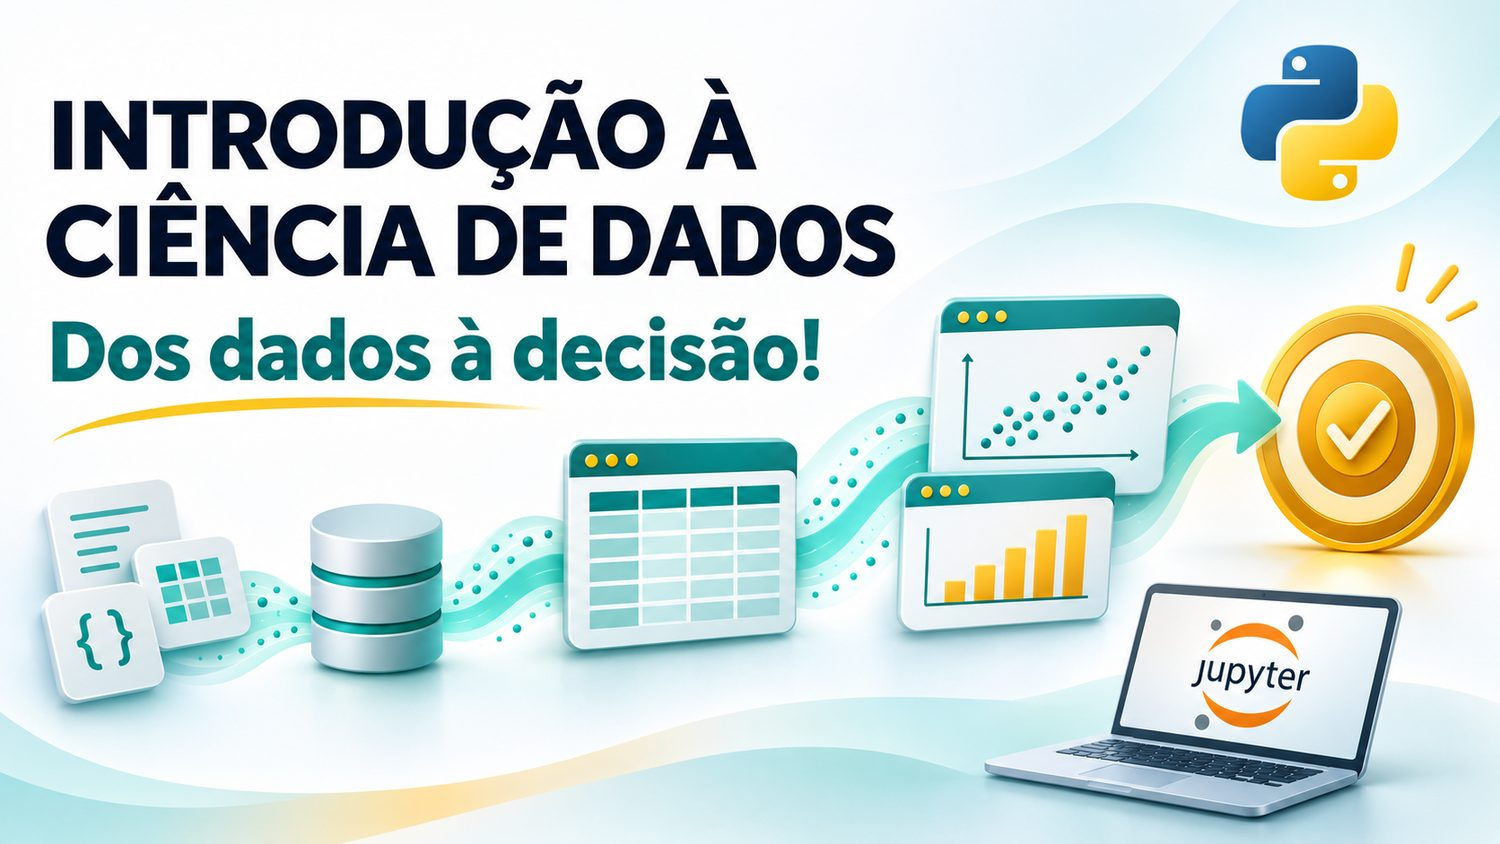

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_6_modelos_supervisionados/07_Florestas_Aleatorias.ipynb)

# Capítulo 7 – Florestas aleatórias

Uma árvore de decisão é fácil de ler e muda muito com pequenas alterações nos dados (capítulo 4). Em vez de combater essa instabilidade, as **florestas aleatórias** tiram partido dela: treinam centenas de árvores diferentes e fazem a média das suas previsões. O resultado é um dos modelos mais usados em dados tabulares. Este capítulo constrói uma floresta de raiz, peça a peça.

> **Objetivos:** perceber porque a média de muitos modelos instáveis é estável; criar amostras *bootstrap*; implementar o *bagging* de raiz; perceber o papel do sorteio de atributos em cada divisão; usar o erro *out-of-bag*; conhecer os hiperparâmetros principais; medir a importância dos atributos por permutação; saber o que se ganha e o que se perde em relação a uma árvore.

**Pré-requisitos:** capítulos 4 a 6. Outra apresentação do mesmo tema: [Árvores, florestas e boosting](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_15_Arvores_Florestas_Boosting.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

## A ideia: perguntar a muita gente

No capítulo 5, treinámos a mesma árvore em 200 amostras diferentes de um mundo simulado. Cada árvore sem limite de profundidade era muito irregular, mas a **média** de todas acompanhava a verdade quase na perfeição. Recuperamos esse mundo: o tempo de entrega em função da hora de saída.

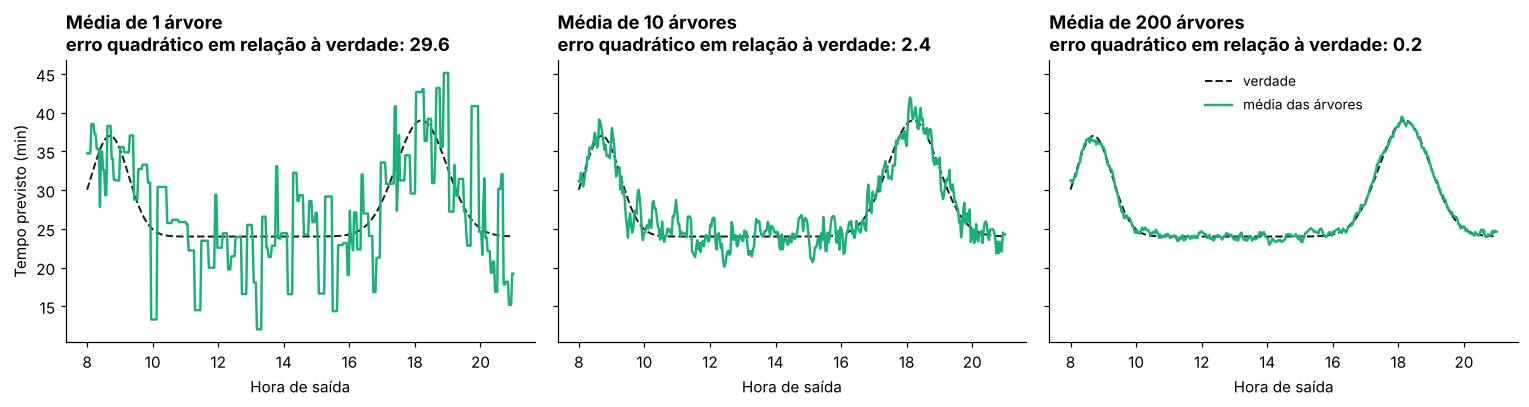

In [2]:
from sklearn.tree import DecisionTreeRegressor


def tempo_esperado(hora):
    hora = np.asarray(hora, dtype=float)
    return 24 + 13 * np.exp(-((hora - 8.7) / 0.8) ** 2) + 15 * np.exp(-((hora - 18.2) / 1.1) ** 2)


def amostrar(n, rng, ruido=5.0):
    hora = np.sort(rng.uniform(8, 21, n))
    return hora.reshape(-1, 1), tempo_esperado(hora) + rng.normal(0, ruido, n)


horas = np.linspace(8, 21, 400).reshape(-1, 1)
verdade = tempo_esperado(horas.ravel())
gerador = np.random.default_rng(0)
arvores = np.array([DecisionTreeRegressor(random_state=0).fit(*amostrar(120, gerador)).predict(horas) for _ in range(200)])

fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, n in zip(eixos, [1, 10, 200]):
    media = arvores[:n].mean(axis=0)
    ax.plot(horas, verdade, color=TINTA, ls="--", lw=1.3, label="verdade")
    ax.plot(horas, media, color=VERDE, lw=1.6, label="média das árvores")
    ax.set_title(f"Média de {n} árvore{'s' if n > 1 else ''}\nerro quadrático em relação à verdade: {np.mean((media - verdade) ** 2):.1f}")
    ax.set_xlabel("Hora de saída")
eixos[0].set_ylabel("Tempo previsto (min)")
eixos[2].legend(frameon=False, loc="upper center", fontsize=9)
plt.tight_layout()
plt.show()

Uma árvore sozinha erra muito, para cima e para baixo. Como os erros de árvores diferentes apontam em sentidos diferentes, **anulam-se** na média. Com 200 árvores, a curva quase coincide com a verdade.

Na linguagem do capítulo 5: cada árvore funda tem **pouco viés e muita variância**. Fazer a média não mexe no viés e reduz a variância. É a combinação ideal.

Há um problema prático: aqui cada árvore foi treinada com uma amostra **nova** do mundo. Na vida real só temos **uma** amostra.

## Bootstrap: fabricar amostras a partir de uma

A solução é simular amostras novas **reamostrando a que temos**. Uma amostra **bootstrap** obtém-se tirando n observações ao acaso, **com reposição**, de um conjunto de n: algumas saem repetidas e outras ficam de fora.

In [3]:
rng = np.random.default_rng(1)
exemplo = rng.integers(0, 10, 10)                             # 10 posições sorteadas entre 0 e 9, com reposição
print("Posições sorteadas:        ", np.sort(exemplo))
print("Ficaram de fora:           ", sorted(int(i) for i in set(range(10)) - set(exemplo.tolist())))

n = 2000
de_fora = [1 - len(np.unique(rng.integers(0, n, n))) / n for _ in range(200)]
print(f"\nEm amostras bootstrap de {n} observações, ficam de fora em média {np.mean(de_fora):.1%} das observações.")

Posições sorteadas:         [0 1 2 3 4 5 7 8 9 9]
Ficaram de fora:            [6]

Em amostras bootstrap de 2000 observações, ficam de fora em média 36.8% das observações.


Em média, cada amostra bootstrap contém cerca de 63% das observações originais (algumas repetidas) e deixa de fora cerca de 37%. Cada amostra é uma versão ligeiramente diferente dos dados: suficiente para a árvore treinada com ela ser diferente das outras.

## Bagging de raiz

Juntando as duas ideias obtém-se o **bagging** (de *bootstrap aggregating*):

1. criar muitas amostras bootstrap do treino;
2. treinar uma árvore funda em cada uma;
3. prever com a **média** das árvores (regressão) ou com a **votação** (classificação).

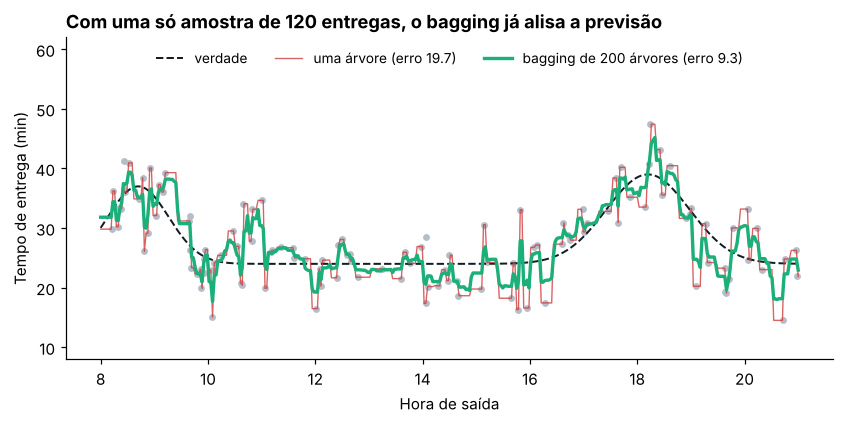

In [4]:
def bagging(X, y, n_arvores=100, semente=0, **opcoes):
    """Treina n_arvores árvores, cada uma numa amostra bootstrap. Devolve a lista de árvores."""
    rng = np.random.default_rng(semente)
    X, y = np.asarray(X), np.asarray(y)
    arvores = []
    for i in range(n_arvores):
        posicoes = rng.integers(0, len(X), len(X))            # amostra bootstrap
        arvores.append(DecisionTreeRegressor(random_state=i, **opcoes).fit(X[posicoes], y[posicoes]))
    return arvores


def prever_floresta(arvores, X):
    return np.mean([arvore.predict(np.asarray(X)) for arvore in arvores], axis=0)


X1, y1 = amostrar(120, np.random.default_rng(11))             # uma única amostra, como na vida real
uma = DecisionTreeRegressor(random_state=0).fit(X1, y1)
floresta_1d = bagging(X1, y1, n_arvores=200)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.scatter(X1, y1, s=12, color=CINZA)
ax.plot(horas, verdade, color=TINTA, ls="--", lw=1.3, label="verdade")
ax.plot(horas, uma.predict(horas), color=MAU, lw=0.9, alpha=0.8, label=f"uma árvore (erro {np.mean((uma.predict(horas) - verdade) ** 2):.1f})")
ax.plot(horas, prever_floresta(floresta_1d, horas), color=VERDE, lw=2.2, label=f"bagging de 200 árvores (erro {np.mean((prever_floresta(floresta_1d, horas) - verdade) ** 2):.1f})")
ax.set_xlabel("Hora de saída")
ax.set_ylabel("Tempo de entrega (min)")
ax.set_ylim(8, 62)
ax.set_title("Com uma só amostra de 120 entregas, o bagging já alisa a previsão")
ax.legend(frameon=False, loc="upper center", ncol=3, fontsize=9)
plt.show()

Com as mesmas 120 entregas, a previsão do bagging é mais suave e mais próxima da verdade do que a de uma árvore. Não chega à qualidade da média de 200 amostras independentes: as amostras bootstrap vêm todas dos mesmos dados e por isso as árvores **parecem-se** umas com as outras. Os seus erros não se anulam por completo.

## Das amostras aos atributos: a floresta aleatória

A média reduz tanto mais a variância quanto **menos correlacionadas** forem as árvores. Com vários atributos há um problema: se um deles for muito forte, quase todas as árvores começam por ele, e ficam parecidas.

A **floresta aleatória** acrescenta um segundo sorteio. Em cada divisão de cada árvore, só uma **parte dos atributos, escolhida ao acaso**, pode ser usada. Cada árvore fica um pouco pior, e todas ficam mais diferentes entre si. Na média, costuma compensar.

Passamos às entregas, com todos os atributos.

In [5]:
def gerar_entregas(n=4000, semente=29):
    """Gera entregas de uma empresa fictícia de distribuição urbana (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    distancia = rng.gamma(2.2, 2.6, n).clip(0.4, 25).round(1)
    hora = rng.uniform(8, 21, n).round(2)
    paragens = rng.poisson(1.2, n)
    peso = rng.gamma(1.6, 3.0, n).clip(0.1, 30).round(1)
    chuva = rng.random(n) < 0.2
    zona = rng.choice(["centro", "periferia", "rural"], n, p=[0.5, 0.35, 0.15])
    veiculo = np.where(distancia < 3, rng.choice(["bicicleta", "mota"], n, p=[0.6, 0.4]),
                       rng.choice(["mota", "carrinha"], n, p=[0.55, 0.45]))
    hora_de_ponta = ((hora >= 8) & (hora < 9.5)) | ((hora >= 17) & (hora < 19.5))
    transito = np.where(hora_de_ponta, np.where(zona == "centro", 1.75, 1.45), 1.0)
    por_km = np.select([veiculo == "bicicleta", veiculo == "mota"], [4.2, 2.9], 3.3)
    tempo = (7 + distancia * por_km * transito * np.where(chuva, 1.25, 1.0) * np.where(zona == "rural", 0.85, 1.0)
             + 4.0 * paragens + 0.15 * peso + rng.normal(0, 3.5, n))
    tempo = np.where(rng.random(n) < 0.015, tempo + rng.uniform(40, 120, n), tempo)       # avarias e enganos de morada
    prometido = 16 + 3.6 * distancia + 4.0 * paragens
    return pd.DataFrame({"distancia_km": distancia, "hora": hora, "paragens": paragens, "peso_kg": peso,
                         "chuva": chuva, "zona": zona, "veiculo": veiculo,
                         "tempo_min": tempo.clip(4).round(1), "atrasada": tempo > prometido})


entregas = gerar_entregas()
entregas.head()

,distancia_km,hora,paragens,peso_kg,chuva,zona,veiculo,tempo_min,atrasada
0,3.6,9.05,3,2.2,False,periferia,carrinha,35.7,False
1,4.3,16.95,0,12.8,False,centro,mota,25.3,False
2,5.1,14.79,1,3.9,True,periferia,carrinha,34.0,False
3,6.0,8.43,1,9.8,False,periferia,mota,44.0,True
4,7.2,14.07,0,2.4,False,centro,mota,33.5,False


Treino: 2400 | validação: 800 | teste: 800 | atributos: 11


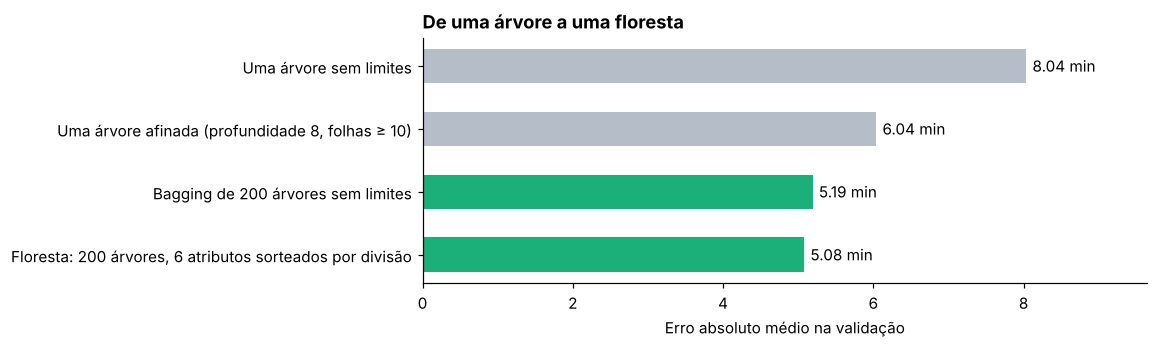

In [6]:
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

numericas, nominais = ["distancia_km", "hora", "paragens", "peso_kg", "chuva"], ["zona", "veiculo"]
tabela = pd.get_dummies(entregas[numericas + nominais], columns=nominais).astype(float)       # árvores não precisam de normalização
atributos = list(tabela.columns)
X_dev, X_teste, y_dev, y_teste = train_test_split(tabela, entregas["tempo_min"], test_size=0.2, random_state=3)
X_treino, X_validacao, y_treino, y_validacao = train_test_split(X_dev, y_dev, test_size=0.25, random_state=0)
print(f"Treino: {len(X_treino)} | validação: {len(X_validacao)} | teste: {len(X_teste)} | atributos: {len(atributos)}")

tentativas = {"Uma árvore sem limites": [DecisionTreeRegressor(random_state=0).fit(X_treino.to_numpy(), y_treino)],
              "Uma árvore afinada (profundidade 8, folhas ≥ 10)": [DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=0).fit(X_treino.to_numpy(), y_treino)],
              "Bagging de 200 árvores sem limites": bagging(X_treino, y_treino, 200),
              "Floresta: 200 árvores, 6 atributos sorteados por divisão": bagging(X_treino, y_treino, 200, max_features=6)}
erros = {nome: mean_absolute_error(y_validacao, prever_floresta(arvores, X_validacao)) for nome, arvores in tentativas.items()}

fig, ax = plt.subplots(figsize=(8.5, 2.9))
barras = ax.barh(list(erros), list(erros.values()), color=[CINZA, CINZA, VERDE, VERDE], height=0.55)
ax.bar_label(barras, fmt="%.2f min", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, max(erros.values()) * 1.2)
ax.set_xlabel("Erro absoluto médio na validação")
ax.set_title("De uma árvore a uma floresta")
plt.show()

A nossa floresta de raiz são as mesmas dez linhas do bagging, com a opção `max_features` passada a cada árvore. Lendo de cima para baixo: a árvore sem limites sobreajusta; afiná-la ajuda; o bagging de árvores sem limites faz melhor do que a árvore afinada; e o sorteio de atributos dá mais um pequeno ganho.

Repara que as árvores do bagging e da floresta **não foram afinadas**: são fundas, cada uma sobreajusta, e é a média que trata do problema.

No scikit-learn:

In [7]:
from sklearn.ensemble import RandomForestRegressor

floresta = RandomForestRegressor(n_estimators=200, max_features=6, random_state=0, n_jobs=-1).fit(X_treino, y_treino)
print(f"RandomForestRegressor: MAE na validação {mean_absolute_error(y_validacao, floresta.predict(X_validacao)):.2f} min | a nossa: {erros['Floresta: 200 árvores, 6 atributos sorteados por divisão']:.2f} min")

RandomForestRegressor: MAE na validação 5.11 min | a nossa: 5.08 min


Os dois valores ficam muito próximos (os sorteios não são os mesmos).

## Quantas árvores?

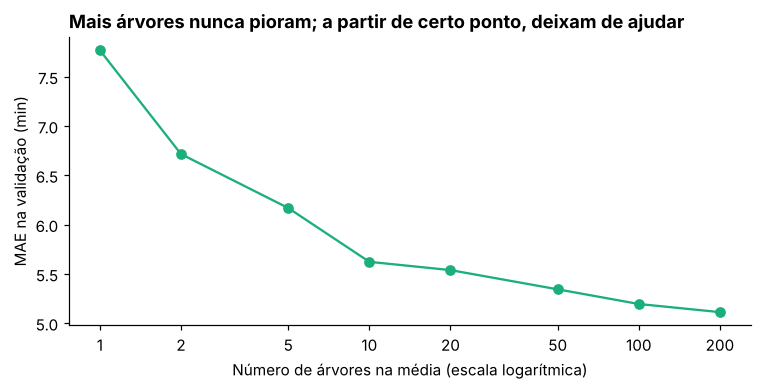

In [8]:
todas_as_arvores = np.array([arvore.predict(X_validacao.to_numpy()) for arvore in floresta.estimators_])
contagens = [1, 2, 5, 10, 20, 50, 100, 200]
curva = [mean_absolute_error(y_validacao, todas_as_arvores[:n].mean(axis=0)) for n in contagens]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(contagens, curva, "o-", color=VERDE)
ax.set_xscale("log")
ax.set_xticks(contagens, contagens)
ax.minorticks_off()
ax.set_xlabel("Número de árvores na média (escala logarítmica)")
ax.set_ylabel("MAE na validação (min)")
ax.set_title("Mais árvores nunca pioram; a partir de certo ponto, deixam de ajudar")
plt.show()

O erro desce depressa com as primeiras árvores e depois cada vez mais devagar. Ao contrário da profundidade de uma árvore ou do k de um KNN, **o número de árvores não causa sobreajuste**: cada árvore nova só torna a média mais estável. O único custo é o tempo. Na prática escolhe-se um número suficiente para a curva estabilizar (algumas centenas).

## Validação de borla: o erro *out-of-bag*

Cada árvore foi treinada sem cerca de 37% das observações de treino. Para essas observações, a árvore é um modelo que **nunca as viu**. Prevendo cada observação apenas com as árvores que não a usaram, obtém-se uma estimativa do erro em dados novos **sem separar nenhuma validação**. Chama-se erro ***out-of-bag*** (OOB).

In [9]:
com_oob = RandomForestRegressor(n_estimators=200, max_features=6, oob_score=True, random_state=0, n_jobs=-1).fit(X_treino, y_treino)
print(f"MAE no treino:        {mean_absolute_error(y_treino, com_oob.predict(X_treino)):.2f} min   (otimista: as árvores viram estes dados)")
print(f"MAE out-of-bag:       {mean_absolute_error(y_treino, com_oob.oob_prediction_):.2f} min   (calculado só com o treino)")
print(f"MAE na validação:     {mean_absolute_error(y_validacao, com_oob.predict(X_validacao)):.2f} min")

MAE no treino:        1.98 min   (otimista: as árvores viram estes dados)
MAE out-of-bag:       5.34 min   (calculado só com o treino)
MAE na validação:     5.11 min


O erro de treino de uma floresta é sempre muito baixo e não diz nada. O erro out-of-bag fica perto do da validação, e sai «de borla» do próprio treino. É útil com poucos dados, quando custa pôr uma parte de lado.

## Os hiperparâmetros que contam

| Hiperparâmetro | O que faz | Regra prática |
| --- | --- | --- |
| `n_estimators` | Número de árvores | Algumas centenas; mais nunca prejudica |
| `max_features` | Atributos sorteados em cada divisão | Menos = árvores mais diferentes. Experimentar entre um terço e todos |
| `min_samples_leaf` | Mínimo de casos por folha | 1 por omissão; valores maiores alisam e aceleram |
| `max_depth` | Profundidade máxima | Sem limite por omissão; raramente é preciso mexer |

In [10]:
linhas = []
for max_features in [1, 2, 4, 6, len(atributos)]:
    for folha in [1, 5, 20]:
        m = RandomForestRegressor(n_estimators=200, max_features=max_features, min_samples_leaf=folha, oob_score=True, random_state=0, n_jobs=-1).fit(X_treino, y_treino)
        linhas.append({"max_features": max_features, "min_samples_leaf": folha, "MAE": mean_absolute_error(y_treino, m.oob_prediction_)})
grelha = pd.DataFrame(linhas).pivot(index="max_features", columns="min_samples_leaf", values="MAE")
print("MAE out-of-bag (min):")
grelha.round(2)

MAE out-of-bag (min):


min_samples_leaf,1,5,20
max_features,,,
1,6.23,6.66,7.98
2,5.91,6.22,7.12
4,5.43,5.50,6.17
6,5.34,5.33,5.93
11,5.52,5.24,5.84


Com um só atributo sorteado por divisão, as árvores são quase aleatórias e a floresta é fraca. A partir de um certo número, as diferenças entre configurações são de décimas de minuto: uma floresta funciona bem quase sem afinação, o que é uma das razões da sua popularidade. Escolhemos a melhor pelo erro out-of-bag, sem tocar na validação.

Nestes dados, a melhor configuração usa **todos** os atributos em cada divisão, com folhas de pelo menos cinco casos: é um bagging, sem sorteio de atributos. Com poucos atributos e um deles (a distância) muito mais forte do que os outros, escondê-lo em parte das divisões custa mais do que rende. O sorteio compensa sobretudo quando há muitos atributos com informação parecida.

## Que atributos contam? A importância por permutação

Uma floresta não se desenha como uma árvore. Para saber o que ela usa, há duas medidas.

- A **importância por impureza**, que já vimos no capítulo 4: a redução de impureza devida a cada atributo, agora em média sobre todas as árvores. É rápida, é calculada no treino, e tende a favorecer atributos com muitos valores distintos.
- A **importância por permutação**: baralha-se uma coluna dos dados de validação e mede-se **quanto piora o erro**. Se o modelo não dependia dela, nada muda.

A segunda implementa-se em poucas linhas e serve para **qualquer** modelo.

Configuração escolhida: max_features = 11, min_samples_leaf = 5


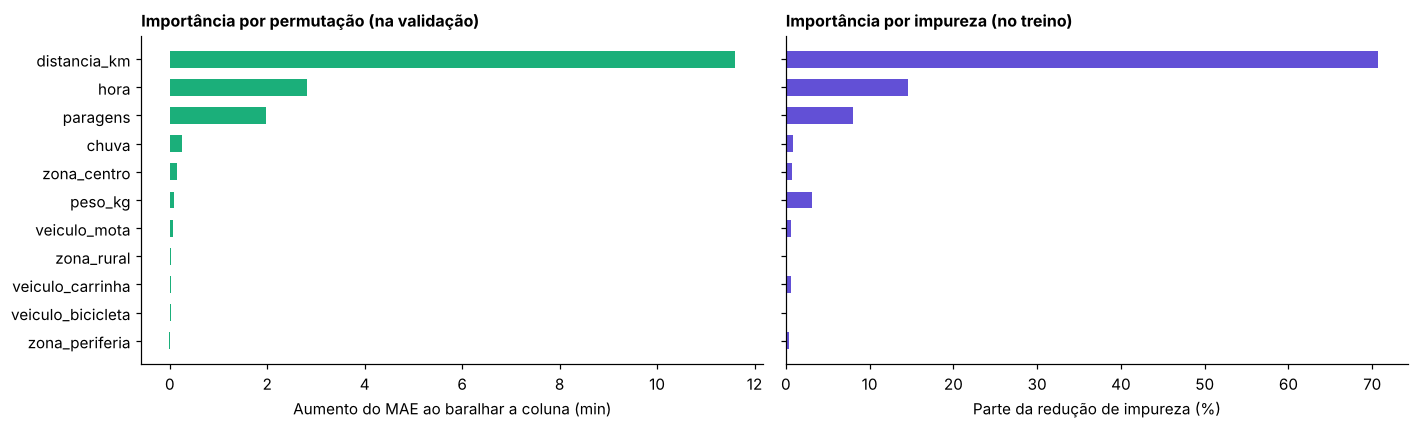

In [11]:
melhor = grelha.stack().idxmin()
final = RandomForestRegressor(n_estimators=300, max_features=int(melhor[0]), min_samples_leaf=int(melhor[1]), random_state=0, n_jobs=-1).fit(X_treino, y_treino)
print(f"Configuração escolhida: max_features = {melhor[0]}, min_samples_leaf = {melhor[1]}")


def importancia_por_permutacao(modelo, X, y, repeticoes=5, semente=0):
    """Aumento do erro absoluto médio quando se baralha cada coluna."""
    rng = np.random.default_rng(semente)
    base = mean_absolute_error(y, modelo.predict(X))
    aumentos = {}
    for coluna in X.columns:
        erros = []
        for _ in range(repeticoes):
            baralhado = X.copy()
            baralhado[coluna] = rng.permutation(baralhado[coluna].to_numpy())
            erros.append(mean_absolute_error(y, modelo.predict(baralhado)))
        aumentos[coluna] = np.mean(erros) - base
    return pd.Series(aumentos)


permutacao = importancia_por_permutacao(final, X_validacao, y_validacao).sort_values()
impureza = pd.Series(final.feature_importances_, index=atributos)[permutacao.index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
ax1.barh(permutacao.index, permutacao, color=VERDE, height=0.6)
ax1.set_xlabel("Aumento do MAE ao baralhar a coluna (min)")
ax1.set_title("Importância por permutação (na validação)", fontsize=10.5)
ax2.barh(impureza.index, impureza * 100, color=VIOLETA, height=0.6)
ax2.set_xlabel("Parte da redução de impureza (%)")
ax2.set_title("Importância por impureza (no treino)", fontsize=10.5)
plt.tight_layout()
plt.show()

A importância por permutação tem uma leitura direta: baralhar a distância piora a previsão em vários minutos; baralhar o peso quase não a altera.

Os mesmos cuidados do capítulo 4 continuam a valer: a importância diz o que **este modelo** usa, e não o que causa os atrasos; e, com dois atributos correlacionados, baralhar um deles pode ser compensado pelo outro, e ambos parecem menos importantes do que são.

## Classificação

Tudo funciona da mesma maneira para classificar. Cada árvore vota, e a fração de votos é a probabilidade.

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.tree import DecisionTreeClassifier

a_dev, a_teste = entregas.loc[X_dev.index, "atrasada"], entregas.loc[X_teste.index, "atrasada"]
a_treino, a_validacao = entregas.loc[X_treino.index, "atrasada"], entregas.loc[X_validacao.index, "atrasada"]
classificadores = {"Árvore afinada (profundidade 8, folhas ≥ 10)": DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=0),
                   "Floresta aleatória (300 árvores)": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=0, n_jobs=-1)}
linhas = {}
for nome, modelo in classificadores.items():
    modelo.fit(X_treino, a_treino)
    prob = modelo.predict_proba(X_validacao)[:, 1]
    linhas[nome] = {"AUC": roc_auc_score(a_validacao, prob), "F1 (limiar 0,5)": f1_score(a_validacao, prob >= 0.5), "melhor F1 (qualquer limiar)": max(f1_score(a_validacao, prob >= t) for t in np.linspace(0.1, 0.7, 25))}
pd.DataFrame(linhas).T.round(3)

,AUC,"F1 (limiar 0,5)",melhor F1 (qualquer limiar)
"Árvore afinada (profundidade 8, folhas ≥ 10)",0.897,0.714,0.739
Floresta aleatória (300 árvores),0.929,0.708,0.779


As probabilidades de uma floresta são médias de centenas de votos, e por isso muito mais finas do que as de uma árvore, que só pode devolver tantos valores quantas folhas tem. Isso nota-se sobretudo na AUC, que mede a ordenação. Com classes desequilibradas, o limiar de 0,5 raramente é o melhor: convém escolhê-lo, como no capítulo 1.

## O teste

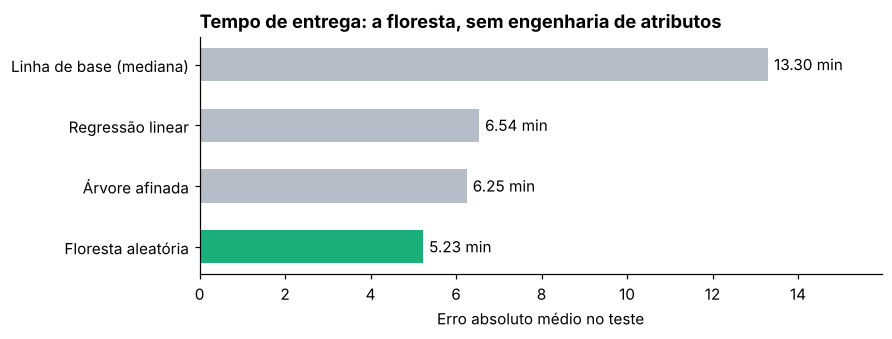

In [13]:
from sklearn.linear_model import LinearRegression

arvore_afinada = DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=0).fit(X_dev, y_dev)
floresta_final = RandomForestRegressor(n_estimators=300, max_features=int(melhor[0]), min_samples_leaf=int(melhor[1]), random_state=0, n_jobs=-1).fit(X_dev, y_dev)
resultado = {"Linha de base (mediana)": mean_absolute_error(y_teste, np.full(len(y_teste), y_dev.median())),
             "Regressão linear": mean_absolute_error(y_teste, LinearRegression().fit(X_dev, y_dev).predict(X_teste)),
             "Árvore afinada": mean_absolute_error(y_teste, arvore_afinada.predict(X_teste)),
             "Floresta aleatória": mean_absolute_error(y_teste, floresta_final.predict(X_teste))}

fig, ax = plt.subplots(figsize=(8, 2.8))
barras = ax.barh(list(resultado), list(resultado.values()), color=[CINZA, CINZA, CINZA, VERDE], height=0.55)
ax.bar_label(barras, fmt="%.2f min", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, max(resultado.values()) * 1.2)
ax.set_xlabel("Erro absoluto médio no teste")
ax.set_title("Tempo de entrega: a floresta, sem engenharia de atributos")
plt.show()

A floresta bate a árvore afinada e a regressão linear com os atributos tal como estão, sem que ninguém lhe tenha dito que existem horas de ponta.

Convém lembrar o capítulo 4: a regressão linear a que demos o atributo `hora_de_ponta` e a sua interação com a distância chegou a um erro ainda mais baixo do que este. Um modelo mais potente encontra sozinho parte da estrutura; não substitui o conhecimento do problema.

## O que se ganha e o que se perde

| | Uma árvore | Uma floresta |
| --- | --- | --- |
| Exatidão | Modesta | Em geral melhor |
| Estabilidade | Muda com pequenas alterações nos dados | Estável |
| Afinação | Sensível à profundidade | Funciona bem quase por omissão |
| Interpretação | Lê-se como um conjunto de regras | Só indiretamente (importâncias) |
| Tempo de treino e de previsão | Muito baixo | Centenas de vezes maior (ainda assim, rápido) |
| Extrapolação | Não extrapola | Não extrapola |
| Normalização | Dispensa | Dispensa |

A diferença que mais pesa é a **explicação**. Uma árvore pequena pode ser mostrada a quem decide. Uma floresta é uma caixa mais fechada: sabemos o que usa e quão bem prevê, e não conseguimos seguir o raciocínio de uma previsão. Quando a explicação é um requisito (crédito, saúde, decisões sobre pessoas), essa diferença pode pesar mais do que alguns pontos de exatidão.

## Exercícios

### `Exercício 1` – Quanto fica de fora?

A probabilidade de uma observação concreta **não** ser escolhida num sorteio entre n é 1 − 1/n. Qual é a probabilidade de não ser escolhida em nenhum dos n sorteios de uma amostra bootstrap? Calcula para n = 10, 100 e 10 000. Para que valor tende?

<details>
<summary><b>Ver uma solução possível</b></summary>

É (1 − 1/n)ⁿ.

- n = 10: 0,9¹⁰ ≈ **0,349**.
- n = 100: 0,99¹⁰⁰ ≈ **0,366**.
- n = 10 000: ≈ **0,368**.

Tende para 1/e ≈ 0,368. É daqui que vêm os «cerca de 37%» que ficam de fora de cada amostra bootstrap, e os 63% que entram.

</details>

### `Exercício 2` – Bagging de árvores pequenas

Repete o bagging no mundo simulado (`X1`, `y1`, 200 árvores) com árvores de profundidade 1, usando a opção `max_depth=1`. Compara o erro em relação à verdade com o de **uma** árvore de profundidade 1. Quanto ajuda o bagging, comparado com o que ajudou nas árvores sem limite? Porquê?

In [14]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
uma_pequena = DecisionTreeRegressor(max_depth=1, random_state=0).fit(X1, y1)
muitas_pequenas = bagging(X1, y1, 200, max_depth=1)
print(f"Profundidade 1:  uma árvore {np.mean((uma_pequena.predict(horas) - verdade) ** 2):.1f} | bagging de 200: {np.mean((prever_floresta(muitas_pequenas, horas) - verdade) ** 2):.1f}")
print(f"Sem limite:      uma árvore {np.mean((uma.predict(horas) - verdade) ** 2):.1f} | bagging de 200: {np.mean((prever_floresta(floresta_1d, horas) - verdade) ** 2):.1f}")
```

Com árvores de profundidade 1, o erro continua alto depois do bagging. Uma árvore tão pequena falha por **viés**: é simples de mais para as duas horas de ponta, e todas as árvores falham da mesma maneira. A média de modelos que erram no mesmo sentido erra nesse sentido. O bagging reduz a variância e não o viés: funciona com modelos flexíveis e instáveis, e pouco faz por modelos demasiado simples. O próximo capítulo trata do caso contrário.

</details>

### `Exercício 3` – A floresta e os atributos inúteis

No capítulo 3, juntar colunas de ruído degradou muito o KNN. Acrescenta 40 colunas de números aleatórios ao treino e à validação e compara o MAE de validação de uma floresta com e sem elas. Calcula a importância por impureza total das 40 colunas de ruído.

In [15]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
rng = np.random.default_rng(0)
ruido = [f"ruido_{i}" for i in range(40)]
Xt = X_treino.assign(**{c: rng.normal(size=len(X_treino)) for c in ruido})
Xv = X_validacao.assign(**{c: rng.normal(size=len(X_validacao)) for c in ruido})
sem = RandomForestRegressor(200, random_state=0, n_jobs=-1).fit(X_treino, y_treino)
com = RandomForestRegressor(200, random_state=0, n_jobs=-1).fit(Xt, y_treino)
print(f"MAE na validação: {mean_absolute_error(y_validacao, sem.predict(X_validacao)):.2f} sem ruído | {mean_absolute_error(y_validacao, com.predict(Xv)):.2f} com 40 colunas de ruído")
print(f"Importância por impureza das 40 colunas de ruído, somada: {pd.Series(com.feature_importances_, index=Xt.columns)[ruido].sum():.0%}")
```

O erro piora menos de um minuto; no capítulo 3, as mesmas 40 colunas levaram o erro do KNN de 6,6 para quase 11 minutos. Em cada divisão, a árvore escolhe o melhor atributo entre os disponíveis, e o ruído raramente ganha: a floresta é muito mais robusta a atributos irrelevantes do que o KNN, sem ser imune. E as colunas de ruído recebem, em conjunto, quase um terço da importância por impureza: nas folhas mais fundas, com poucos casos, uma coluna aleatória consegue «separar» por acaso. É o enviesamento desta medida, e a razão para preferir a importância por permutação.

</details>

### `Exercício 4` – Extrapolar

Treina uma floresta e uma regressão linear para prever `tempo_min` só com `distancia_km`, usando as entregas até 10 km. Prevê para 5, 10, 15 e 25 km. O que faz cada modelo?

In [16]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
curtas = entregas[entregas["distancia_km"] <= 10]
f = RandomForestRegressor(200, min_samples_leaf=20, random_state=0).fit(curtas[["distancia_km"]], curtas["tempo_min"])
l = LinearRegression().fit(curtas[["distancia_km"]], curtas["tempo_min"])
novas = pd.DataFrame({"distancia_km": [5.0, 10.0, 15.0, 25.0]})
print(novas.assign(floresta=f.predict(novas).round(1), linear=l.predict(novas).round(1)))
print("Tempo médio real das entregas entre 14 e 16 km:", entregas.loc[entregas["distancia_km"].between(14, 16), "tempo_min"].mean().round(1))
```

Até aos 10 km, os dois modelos dão valores parecidos. Para lá disso, a floresta devolve sempre o mesmo valor (o das entregas mais longas que viu), e a regressão linear continua a subir, mais perto da realidade. Uma floresta é uma média de árvores, e uma média de patamares continua a ser um patamar: **não extrapola**.

</details>

## Verifica o que aprendeste

- [ ] Sei porque a média de muitas árvores é mais estável do que uma árvore.
- [ ] Sei o que é uma amostra bootstrap.
- [ ] Sei implementar o bagging.
- [ ] Sei o que acrescenta o sorteio de atributos em cada divisão.
- [ ] Sei o que é o erro out-of-bag.
- [ ] Sei porque mais árvores não causam sobreajuste.
- [ ] Sei calcular e interpretar a importância por permutação.
- [ ] Sei o que se ganha e o que se perde em relação a uma árvore.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/ensemble.html#random-forests-and-other-randomized-tree-ensembles
- https://scikit-learn.org/stable/modules/permutation_importance.html
- https://en.wikipedia.org/wiki/Random_forest
- https://en.wikipedia.org/wiki/Bootstrap_aggregating